# Condition-specific parameters

The same model is often fitted to several conditions: a wild type and mutants, untreated and treated cells, different cell lines.
Most parameters should be the same in all conditions, and a few differ.
Which ones?
Trying every combination of shared and condition-specific parameters means $2^{n}$ joint fits for $n$ parameter-condition pairs.

`select.condition_specific` finds them from a single scan (L1 regularisation, Steiert et al. 2016, *Bioinformatics* 32(17)):

1. Each candidate parameter $k$ gets a log fold-change per non-reference condition, $k_c = k \cdot e^{fc_c}$.
2. All conditions are fitted jointly with an L1 penalty $\lambda \sum |fc|$, which pulls most fold-changes to exactly zero.
   Solving for decreasing $\lambda$ gives the **regularisation path**: the order in which parameters become condition-specific.
3. Every distinct structure on the path is refitted without the penalty.
4. The most parsimonious structure that still fits is selected, by a likelihood-ratio test against the full model (all fold-changes free) or an information criterion.

In [1]:
import numpy as np

from mxlpy import Model, Simulator, fit, fns, plot, select

As an example, a chain $x \to y \to z \to \varnothing$ is measured in three conditions.
In the mutant, $k_2$ is doubled. Under stress, $k_2$ is doubled as well and $k_3$ is halved.

In [2]:
def chain() -> Model:
    return (
        Model()
        .add_parameters({"k1": 0.5, "k2": 2.0, "k3": 1.0})
        .add_variables({"x": 2.0, "y": 0.0, "z": 0.0})
        .add_reaction(
            "v1", fns.mass_action_1s, args=["x", "k1"], stoichiometry={"x": -1, "y": 1}
        )
        .add_reaction(
            "v2", fns.mass_action_1s, args=["y", "k2"], stoichiometry={"y": -1, "z": 1}
        )
        .add_reaction(
            "v3", fns.mass_action_1s, args=["z", "k3"], stoichiometry={"z": -1}
        )
    )


sigma = 0.01
times = np.linspace(0.2, 6.0, 15)
rng = np.random.default_rng(42)


def measure(**parameters: float):
    model = chain().update_parameters(parameters)
    res = Simulator(model).simulate_time_course(times).get_result().unwrap_or_err()
    df = res.get_combined().loc[times, ["x", "y", "z"]]
    return df + rng.normal(0, sigma, df.shape)


conditions = {
    "wt": fit.FitSettings(chain(), measure()),
    "mut": fit.FitSettings(chain(), measure(k2=4.0)),
    "stress": fit.FitSettings(chain(), measure(k2=4.0, k3=0.5)),
}

## Regularisation path

Each condition is a `fit.FitSettings`, so the conditions can use different models (e.g. a knock-out), initial conditions or protocols.
As in `select.run`, a Series fits a steady state, a DataFrame a time course and settings with a `protocol` a protocol time course.
The estimated parameters `p0` are shared by all conditions, and the `candidates` among them may differ.
The selection compares likelihoods, so it needs a likelihood loss.

By default, the path has 20 penalty strengths, from just above $\lambda_{max}$ (from which all fold-changes are zero) down to $\lambda_{max} / 1000$.

In [3]:
res = select.condition_specific(
    conditions,
    p0={"k1": 1.0, "k2": 1.0, "k3": 1.0},
    candidates=["k1", "k2", "k3"],
    loss_fn=fit.GaussianNll(sigma),
    reference="wt",
)

refits:   0%|          | 0/3 [00:00<?, ?it/s]

refits:  33%|███▎      | 1/3 [00:01<00:03,  1.68s/it]

refits: 100%|██████████| 3/3 [00:01<00:00,  1.78it/s]

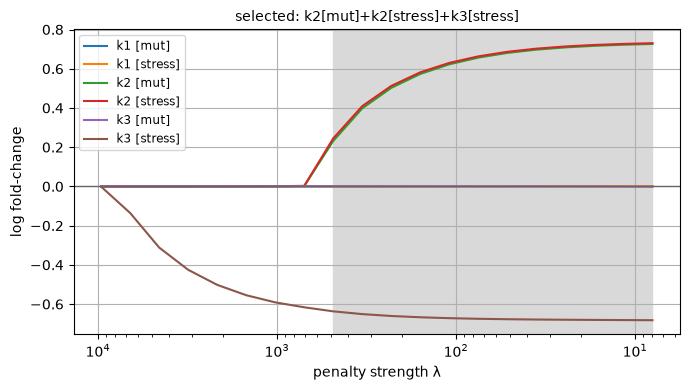

In [4]:
_ = plot.condition_specific_path(res)

The path shows the log fold-changes from strong (left) to weak penalty (right).
At the strongest penalties all parameters are shared.
$k_3$ in the stress condition is the first to differ, followed by $k_2$ in both mutant and stress, while $k_1$ stays shared along the whole path.
The shaded range has the selected structure.

`res.path` holds the fold-changes and `res.path_fits` the loss and structure of every path solution.

In [5]:
res.path_fits

,loss,penalty,structure
lambda,,,
9605.481422,3357.668249,8.917639,shared
6613.889968,2374.798537,892.337800,k3[stress]
4554.018543,1387.364531,1416.925171,k3[stress]
3135.686410,950.584379,1331.490417,k3[stress]
2159.088543,747.205599,1082.636437,k3[stress]
1486.648449,650.761465,824.120534,k3[stress]
1023.637320,604.534077,605.173108,k3[stress]
704.829285,580.608850,436.374450,k2[stress]+k3[stress]
485.312827,298.189444,539.494446,k2[mut]+k2[stress]+k3[stress]


## Selection

Every distinct structure on the path, plus the fully shared and the full model, is refitted without the penalty, with the zero fold-changes fixed.
With `criterion="lrt"` (the default), the most parsimonious structure that a likelihood-ratio test against the full model doesn't reject (`significance=0.05`) is selected.
The table lists all refits (`res.fits`) with their criteria and the p-values of these tests.

In [6]:
res.table

,k,n,log_likelihood,aic,aicc,bic,p_value,lambda
structure,,,,,,,,
shared,3,135,-3372.022126,6750.044252,6750.227458,6758.760076,0.000000e+00,9605.481422
k3[stress],4,135,-564.207269,1136.414538,1136.722231,1148.035638,2.820439e-224,6613.889968
k2[stress]+k3[stress],5,135,-425.991094,861.982189,862.447305,876.508562,1.281508e-165,704.829285
k2[mut]+k2[stress]+k3[stress],6,135,-40.481534,92.963067,93.619317,110.394716,9.686373e-01,485.312827
k1[mut]+k1[stress]+k2[mut]+k2[stress]+k3[mut]+k3[stress],9,135,-40.355108,98.710215,100.150215,124.857688,NaN,NaN


In [7]:
res.selected

{'mut': ['k2'], 'stress': ['k2', 'k3']}

`res.best` is the refit of the selected structure. Its `parameters` are the values in each condition, and `res.models()` returns the models with these values set.

In [8]:
res.best.parameters

,k1,k2,k3
wt,0.499846,1.979583,0.996033
mut,0.499846,4.126875,0.996033
stress,0.499846,4.144124,0.503528


`criterion="aic"`, `"aicc"` or `"bic"` select the structure with the lowest criterion instead, and `res.lrt(null, alt)` tests any two nested structures.

In [9]:
res.lrt("k3[stress]")

LikelihoodRatio(statistic=1047.7043234127045, df=5, p_value=2.8204390196729377e-224)

## Variants of the penalty

`regularisation=` chooses the penalty on the fold-changes:

- `"l1"`: the lasso $\lambda \sum |fc|$ (default)
- `"adaptive"`: the adaptive lasso, weighted by $1 / |fc|^{\gamma}$ of the full fit (`gamma=1`), which shrinks large fold-changes less
- `"elastic_net"`: $\lambda \sum (\alpha |fc| + (1 - \alpha) fc^2 / 2)$ with `l1_ratio=`$\alpha$
- `"group"`: the group lasso $\lambda \sum_k \sqrt{n} \, \lVert fc_k \rVert_2$ over the conditions of each parameter, so a parameter differs in all conditions or in none
- `"fused"`: $\lambda \sum_{a < b} |fc_a - fc_b|$ over all pairs of conditions (with $fc = 0$ for the reference), so conditions can share a value that differs from the reference's

The fused lasso finds that mutant and stress share one value of $k_2$, which saves a parameter:

In [10]:
fused = select.condition_specific(
    conditions,
    p0={"k1": 1.0, "k2": 1.0, "k3": 1.0},
    candidates=["k1", "k2", "k3"],
    loss_fn=fit.GaussianNll(sigma),
    regularisation="fused",
)
fused.best_id, fused.best.structure

refits:   0%|          | 0/3 [00:00<?, ?it/s]

refits:  33%|███▎      | 1/3 [00:01<00:03,  1.65s/it]

refits: 100%|██████████| 3/3 [00:01<00:00,  1.82it/s]

('k2[mut,stress]+k3[stress]',
 {'k1': (('wt', 'mut', 'stress'),),
  'k2': (('wt',), ('mut', 'stress')),
  'k3': (('wt', 'mut'), ('stress',))})

In [11]:
fused.best.parameters

,k1,k2,k3
wt,0.499851,1.979585,0.996001
mut,0.499851,4.135943,0.996001
stress,0.499851,4.135943,0.503555


## Notes

- The L1 penalty is smoothed, $|fc| \approx \sqrt{fc^2 + \varepsilon^2} - \varepsilon$ (`smoothing=1e-3`), so all minimizers work (`fit.LeastSquaresMinimizer()` by default).
  Fold-changes within $2\varepsilon$ of zero count as zero (as differences, for the fused lasso).
- The path is solved serially, each fit warm-started from the previous one; the refits run in parallel.
  Each path fit costs about as much as one joint fit, so 20 strengths take about as long as 20 joint fits, while trying all structures takes $2^n$.
- Only structures on the path are refitted, so a coarse grid (`lambdas=` the number of strengths, or explicit strengths) can miss one.
- Start from good shared values: the shared fit warm-starts everything else.
  Give `p0` distributions (e.g. `LogUniform(1e-2, 1e2)`) and `n_starts=10` to fit it from random starts as well (in parallel); `res["shared"].objectives` holds the objective of every start.
- `transform="log"` fits the shared values on a log scale; the fold-changes are logarithmic already.
  `max_fold_change=1e3` bounds them.

The penalties are available for any fit as `fit.L1Penalty` (lasso, elastic net, and fused lasso via `matrix=`) and `fit.GroupL1Penalty`, e.g. for sparse regularisation:

In [12]:
fit.time_course(
    chain(),
    p0={"k1": 1.0, "k2": 1.0, "k3": 1.0},
    data=conditions["wt"].data,
    minimizer=fit.LeastSquaresMinimizer(),
    loss_fn=fit.GaussianNll(sigma),
    penalty=fit.L1Penalty(["k1", "k2", "k3"], weight=10.0),
).unwrap_or_err().best_pars

{'k1': np.float64(0.49910410647399944),
 'k2': np.float64(1.9719469134842171),
 'k3': np.float64(0.9971601342582979)}